# Goldman Sachs — Loan Default Prediction

## Project Objective

The objective of this project is to analyse historical loan data associated with Goldman Sachs, identify patterns associated with loan defaults, and develop a machine learning model to predict potential loan defaults. The project includes data preparation, feature encoding and scaling, model training and evaluation, feature importance analysis, and practical recommendations for loan risk management.

1. Data Inspection and Quality Checks

3. Feature Selection and Train-Test Split


## 3. Feature Selection and Train-Test Split

Relevant loan and customer features are selected to predict historical loan outcomes.

The dataset is divided into 80% training data and 20% testing data. This allows the model to learn from one portion of the data and be evaluated on previously unseen records.


In [ ]:

from sklearn.model_selection import train_test_split

# Convert loan term into numeric months
ml_data["term"] = pd.to_numeric(
    ml_data["term"].astype(str).str.extract(r"(\d+)", expand=False),
    errors="coerce"
)

# Join customer information
customer_columns = [
    "customer_id", "annual_inc", "emp_length",
    "home_ownership", "verification_status",
    "avg_cur_bal", "Tot_cur_bal"
]

ml_data = ml_data.merge(
    customer[customer_columns],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Select numerical and categorical features
numeric_features = [
    "loan_amount", "term", "issue_year",
    "annual_inc", "avg_cur_bal", "Tot_cur_bal"
]

categorical_features = [
    "purpose", "home_ownership",
    "verification_status", "emp_length", "state"
]

X = ml_data[numeric_features + categorical_features]
y = ml_data["default_flag"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X.shape[1])


Total records: 94212
Training records: 75369
Testing records: 18843
Number of features: 11



## 4. Data Preprocessing — Missing Values, Encoding and Scaling

Numerical features are prepared by filling missing values with the median and standardizing their scales. Categorical features are prepared by filling missing values with the most frequent category and converting categories into numerical representations using one-hot encoding.

All preprocessing is fitted on the training data through a pipeline to reduce data leakage into the test set.


In [ ]:

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Process numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")
print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)
print("Missing values are handled by the preprocessing pipeline.")


Preprocessing completed successfully!
Training data after preprocessing: (75369, 90)
Testing data after preprocessing: (18843, 90)
Missing values are handled by the preprocessing pipeline.



## 5. Model Training — Logistic Regression

A Logistic Regression classifier is trained to predict whether a loan will be Fully Paid or Charged Off based on the selected loan and customer features.

Class weighting is used to account for the imbalance between the two outcome classes. The model is trained using the training dataset and evaluated on the separate test dataset.


In [ ]:

from sklearn.linear_model import LogisticRegression

# Build the model using the preprocessing pipeline
model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model using the original training data
model.fit(X_train, y_train)

# Predict outcomes for unseen test records
y_pred = model.predict(X_test)

print("MODEL TRAINING COMPLETED")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Model type: Logistic Regression")
print("Prediction count:", len(y_pred))


MODEL TRAINING COMPLETED
Training records: 75369
Testing records: 18843
Model type: Logistic Regression
Prediction count: 18843



## 6. Model Evaluation — Performance Metrics

The model is evaluated using accuracy, precision, recall, and F1-score. These metrics help assess overall prediction accuracy and how effectively the model identifies loans that were charged off.

Because the dataset contains more Fully Paid loans than Charged Off loans, accuracy alone is not sufficient to judge model performance.


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("MODEL EVALUATION RESULTS")
print(f"Accuracy:  {accuracy:.4f} ({accuracy:.2%})")
print(f"Precision: {precision:.4f} ({precision:.2%})")
print(f"Recall:    {recall:.4f} ({recall:.2%})")
print(f"F1-score:  {f1:.4f} ({f1:.2%})")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fully Paid", "Charged Off"],
    zero_division=0
))


MODEL EVALUATION RESULTS
Accuracy:  0.6355 (63.55%)
Precision: 0.2819 (28.19%)
Recall:    0.5972 (59.72%)
F1-score:  0.3830 (38.30%)

Detailed Classification Report:
              precision    recall  f1-score   support

  Fully Paid       0.87      0.64      0.74     15273
 Charged Off       0.28      0.60      0.38      3570

    accuracy                           0.64     18843
   macro avg       0.58      0.62      0.56     18843
weighted avg       0.76      0.64      0.67     18843




### Final Interpretation — Model Evaluation

The Logistic Regression model achieved 63.55% accuracy on the test dataset. For Charged Off loans, precision was 28.19%, recall was 59.72%, and the F1-score was 38.30%.

The model identified approximately 60% of historical charged-off loans, but many loans flagged as charged off were actually fully paid. This indicates that the model is a baseline rather than a reliable standalone lending decision tool. Further testing and model improvement are required.



## 7. Confusion Matrix — Loan Default Prediction

A confusion matrix compares the actual loan outcomes with the model's predictions. It shows the number of correctly classified loans, false alarms, and missed charged-off loans.


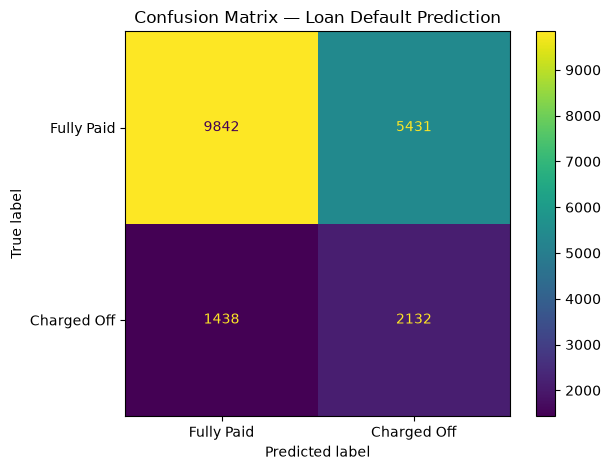

Confusion matrix values:
[[9842 5431]
 [1438 2132]]


In [ ]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fully Paid", "Charged Off"]
)

matrix_display.plot(values_format="d")
plt.title("Confusion Matrix — Loan Default Prediction")
plt.tight_layout()
plt.show()

print("Confusion matrix values:")
print(cm)



### Final Interpretation — Confusion Matrix

The confusion matrix shows that the Logistic Regression model correctly classified 9,842 Fully Paid loans and 2,132 Charged Off loans. However, it incorrectly flagged 5,431 Fully Paid loans as Charged Off and missed 1,438 Charged Off loans.

The model identifies a proportion of historical charged-off loans, but the large number of false alarms indicates that its predictions need improvement. The model should not be used as the sole basis for lending decisions.



## 8. Feature Importance Analysis

This section examines the Logistic Regression model's coefficients to identify features most strongly associated with its predictions. Positive coefficients are associated with predicting Charged Off, while negative coefficients are associated with predicting Fully Paid.

These are model associations, not proof that a feature causes a loan to default.


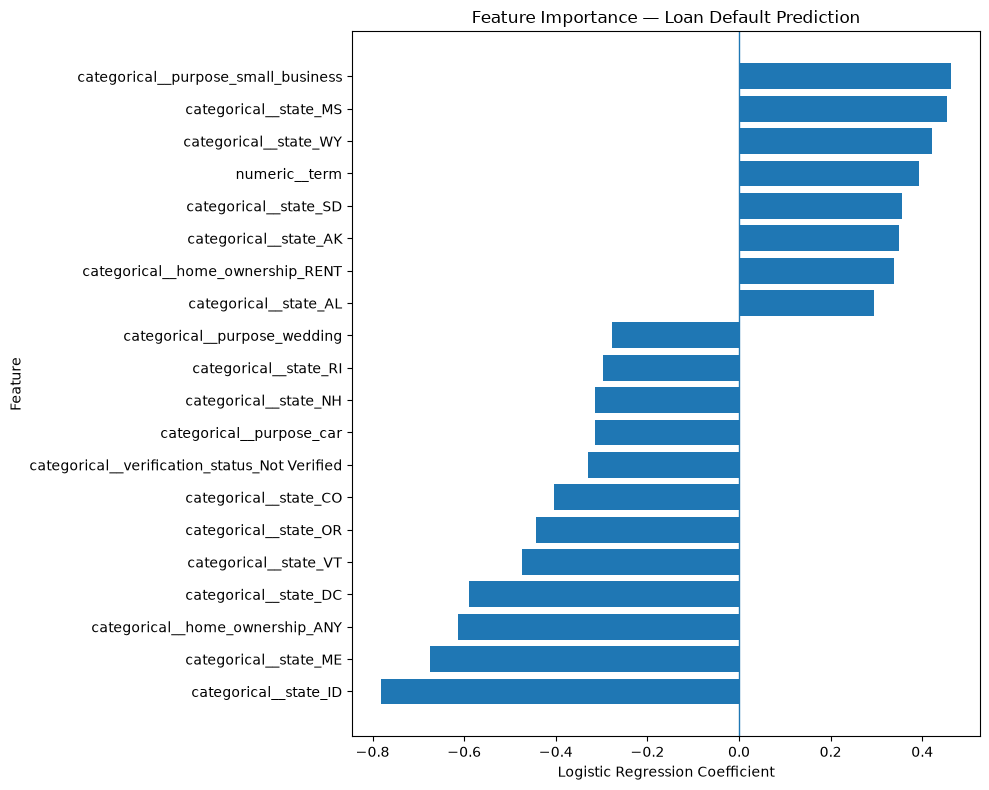

Top 10 features by absolute coefficient:
                            Feature  Coefficient
              categorical__state_ID    -0.782280
              categorical__state_ME    -0.675401
    categorical__home_ownership_ANY    -0.613078
              categorical__state_DC    -0.590258
              categorical__state_VT    -0.473250
categorical__purpose_small_business     0.463766
              categorical__state_MS     0.453085
              categorical__state_OR    -0.444072
              categorical__state_WY     0.421673
              categorical__state_CO    -0.403193


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Get the feature names created by preprocessing
feature_names = model.named_steps[
    "preprocessing"
].get_feature_names_out()

# Extract the trained Logistic Regression coefficients
coefficients = model.named_steps[
    "classifier"
].coef_[0]

# Build a feature-importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

importance_df["Absolute Coefficient"] = (
    importance_df["Coefficient"].abs()
)

# Select the 20 strongest coefficients
top_features = importance_df.nlargest(
    20, "Absolute Coefficient"
).sort_values("Coefficient")

# Create the chart
plt.figure(figsize=(10, 8))
plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)
plt.axvline(0, linewidth=1)
plt.title("Feature Importance — Loan Default Prediction")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Top 10 features by absolute coefficient:")
print(
    importance_df.nlargest(10, "Absolute Coefficient")[
        ["Feature", "Coefficient"]
    ].to_string(index=False)
)



### Final Interpretation — Feature Importance

The Logistic Regression coefficient chart indicates that loan purpose, state, loan term, and home-ownership categories contribute to the model's predictions. The small-business purpose category has a positive coefficient of approximately 0.464, while Idaho has the strongest negative coefficient at approximately -0.782.

Positive coefficients are associated with predicting Charged Off, whereas negative coefficients are associated with predicting Fully Paid. These relationships are conditional on the other features included in the model and do not establish causation. State-level findings should be interpreted cautiously because the number of loans in each category may differ substantially.



## 9. Conclusion and Business Recommendations

### Project Summary

A Logistic Regression model was developed using historical loan records with final outcomes of Fully Paid or Charged Off. The prepared dataset contained 94,212 loans and was divided into training and testing sets. Numerical and categorical features were processed using imputation, scaling, and one-hot encoding.

### Model Performance

The model achieved 63.55% accuracy, 28.19% precision, 59.72% recall, and a 38.30% F1-score for Charged Off loans. The confusion matrix showed that the model identified 2,132 charged-off loans but incorrectly flagged 5,431 fully paid loans as charged off.

These results provide a baseline, but the low precision indicates that many flagged loans were not charged off. The model requires further improvement and validation before it could support lending decisions.

### Business Recommendations

1. Compare Logistic Regression with alternative classification models and evaluate them using precision, recall, F1-score, and confusion matrices.
2. Examine the number of observations in each state and loan-purpose category before making targeted recommendations.
3. Review false positives and false negatives to understand the operational costs of incorrect predictions.
4. Use model predictions as decision-support information rather than as the sole basis for approving or rejecting loans.
5. Obtain richer customer credit-history and repayment data to improve future risk assessment.

### Limitations

The available dataset contains loan outcomes but does not provide genuine application approval/rejection labels. Therefore, an approval-prediction model cannot be reliably trained from these loan outcomes alone.

The analysis identifies statistical associations, not causal relationships. Further testing, validation, and fairness assessment are needed before any real-world deployment.



## 9. Approval Prediction — Data Limitations

The assignment requires a loan approval prediction model. However, the available dataset contains loan repayment outcomes, such as Fully Paid and Charged Off, rather than explicit application decisions indicating Approved or Rejected.

These repayment outcomes cannot be used as substitutes for approval decisions. Therefore, a reliable approval prediction model cannot be trained using the available data alone.

To develop this model, Goldman Sachs would need historical loan application records with genuine approval and rejection labels.


## 10. Conclusion and Business Recommendations

The Logistic Regression model was trained to identify loans that may be charged off using historical loan and customer information.

The model achieved 63.55% accuracy and identified 59.72% of charged-off loans in the test dataset. However, its precision was 28.19%, meaning many loans predicted as charged off were actually fully paid. The model should therefore support, rather than replace, human assessment.

The model's feature analysis showed associations between default predictions and factors such as loan purpose, state, and home ownership. These relationships should be investigated further and should not be treated as proof that any factor causes default.

For loan officers, the model may help identify applications that need additional review. Decisions should also consider verified financial information and fair lending practices.

A reliable loan approval prediction model could not be developed because the available dataset does not contain genuine approved and rejected application labels. Historical application decision data would be required to build that model.

In [ ]:
import os
print(os.path.abspath("caps.ipynb"))